# The grid workflow — three grids, three derivations

An ecoinvent network-construction dataset is priced per km of real line or cable.
PyPSA hands over no such km: it reports the grid as capacity (GW), capacity-length
(GW·km) and route length, on a network clustered to a few dozen nodes.
`rules/grid.smk` bridges that gap once per grid, and the three bridges have
nothing in common but their shape — so each has its own rule, its own table, and
its own section here.

| grid | rule | how it reaches km |
| --- | --- | --- |
| HV AC | `estimate_hv_ac_grid_km` | fractional GW·km growth × the real circuit-km stock |
| HVDC | `estimate_dc_grid_km` | expanded GW·km × clustering correction ÷ cable rating |
| Distribution | `estimate_distribution_grid_km` | (rating growth − 1) × the existing stock |

Each section walks the three stages its rule runs, left to right:

1. **Input** — what PyPSA reports, per scenario.
2. **Derivation** — the step that turns that into a length.
3. **Result** — the km the metal accounting multiplies by a per-km intensity.

*Capacity-equivalent* is the load-bearing word in stage 3: this is the length of
reference-rated conductor whose material carries the modelled capacity growth, not
a count of new geographic route. Much real reinforcement thickens conductors on
existing corridors instead of laying proportional new km.

Two of the three grids also split their km across sub-technologies with a
hand-entered market share; where they do, the section closes with where that
number came from.

Visualisation only — every number is read from a build file or the ecoinvent
store. Run by the `visualise_grid` rule (metal-lci-viz env), or interactively
(paths resolve to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above
from info_schemas import (  # noqa: E402
    DcGridKm,
    DistributionGridKm,
    GridCapacity,
    GridType,
    HvAcGridKm,
    HvdcSubseaShare,
)

try:
    paths = {
        "hv_ac": snakemake.input.hv_ac,  # noqa: F821 — injected by the notebook rule
        "dc": snakemake.input.dc,  # noqa: F821
        "distribution": snakemake.input.distribution,  # noqa: F821
        "combined": snakemake.input.combined,  # noqa: F821
        "subsea_share": snakemake.input.subsea_share,  # noqa: F821
        "market_share_scenarios": snakemake.input.market_share_scenarios,  # noqa: F821
        "lci_info": snakemake.input.lci_info,  # noqa: F821
        "figures": snakemake.output.figures,  # noqa: F821
    }
    technology_info = dict(snakemake.params.technology_info)  # noqa: F821
    lci_project = snakemake.params.lci_project  # noqa: F821
    ecoinvent_db = snakemake.params.ecoinvent_db  # noqa: F821
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    style = config["plotting"]
    lci_project = config["lci"]["project"]
    ei = config["lci"]["ecoinvent"]
    ecoinvent_db = f"ecoinvent-{ei['version']}-{ei['system_model']}"
    paths = dict(
        hv_ac=repo / "build/grid/capacity_km/hv_ac.csv",
        dc=repo / "build/grid/capacity_km/dc.csv",
        distribution=repo / "build/grid/capacity_km/distribution.csv",
        combined=repo / "build/grid/grid_capacity_km.csv",
        subsea_share=repo / "build/grid/hvdc_subsea_share.csv",
        market_share_scenarios=repo / "data/market_share_scenarios.csv",
        lci_info=repo / "data/lci_info.csv",
        figures=repo / "build/grid/figures",
    )

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]

# One entry per grid_type, keyed the way rules/grid.smk keys its rules, so a
# section below and a rule there line up one to one: the technology the grid
# stands for, how it is drawn, and the table its own rule wrote.
grids = {}
for technology, info in technology_info.items():
    if info["capacity_source"] != "grid":
        continue
    grid_type = info["grid_type"]
    grids[grid_type] = dict(
        technology=technology,
        nice_name=info["nice_name"],
        color=info["color"],
        table=pd.read_csv(paths[grid_type]).set_index(GridCapacity.scenario),
    )

scenarios = list(grids[GridType.hv_ac]["table"].index)
{grid_type: grid["technology"] for grid_type, grid in grids.items()}

{'hv_ac': 'grid_hv_ac', 'dc': 'grid_dc', 'distribution': 'grid_distribution'}

In [2]:
# Drawing, shared by the three sections so the same stage reads the same way in
# each. Stage 3 is literally the same panel three times -- it is the one thing the
# three derivations have in common -- while stages 1 and 2 differ per grid and are
# assembled from the pieces below.
GREY = ink["muted"]  # the present-day / as-modelled series a modelled one is set against


def scenario_axis(ax, labels):
    """The scenario names under a panel, at the shared bar-axis geometry."""
    positions = {str(label): float(i) for i, label in enumerate(labels)}
    plotting.category_axis(ax, positions, {key: key for key in positions}, style)


def stage_figure(grid, stage_1, stage_2):
    """The three stages of one grid's rule, one under the other down the page.

    A stage's name is a sentence and its bars are named by scenario at a slant,
    neither of which fits a third of the page's width. The numbering belongs to
    the sequence, so the titles are set here and the drawers pass `title=None`.
    """
    fig, axes = plotting.page_grid(
        3, style, max_columns=1, row_height=style["supplement"]["wide_row"]
    )
    titles = [stage_1, stage_2, "Result — capacity-equivalent km"]
    for number, (ax, title) in enumerate(zip(axes, titles), start=1):
        plotting.panel_title(ax, style, f"{number}. {title}", None)
    return fig, axes


def two_series(ax, before, after, labels, color, ylabel):
    """Grouped bars: a present-day or brownfield series against a modelled one.

    Headroom first, then the legend into it: both stage-1 panels that use this have
    bars running the full height of the axes, so a legend placed over them lands on
    the data.
    """
    positions = range(len(before))
    width = 0.38
    ax.bar([i - width / 2 for i in positions], before.values, width, color=GREY,
           label=labels[0])
    ax.bar([i + width / 2 for i in positions], after.values, width, color=color,
           label=labels[1])
    plotting.style_panel(ax, style, title=None, ylabel=ylabel)
    scenario_axis(ax, before.index)
    ax.margins(y=0.3)
    ax.legend(frameon=False, loc="upper center", ncol=2)


def note(ax, text):
    """What the panel's quantity is multiplied by on its way to the next one."""
    ax.text(0.5, 0.95, text, transform=ax.transAxes, ha="center", va="top",
            style="italic", color=ink["secondary"])


def ratio_panel(ax, ratios, color, ylabel, multiplies):
    """A per-scenario ratio against the no-change line, and what it scales."""
    ax.bar(range(len(ratios)), ratios.values, color=color)
    ax.axhline(1.0, color=ink["secondary"], ls="--", lw=0.8)
    plotting.style_panel(ax, style, title=None, ylabel=ylabel)
    scenario_axis(ax, ratios.index)
    note(ax, multiplies)
    ax.margins(y=0.22)


def result_panel(ax, grid):
    """Stage 3, identical for all three grids: the km its rule wrote."""
    km = grid["table"][GridCapacity.capacity_km] / 1e3
    ax.bar(range(len(km)), km.values, color=grid["color"])
    plotting.style_panel(
        ax, style, title=None, ylabel="Thousand km (capacity-equivalent)"
    )
    scenario_axis(ax, km.index)
    for i, value in enumerate(km.values):
        ax.text(i, value, f"{value:,.0f}", va="bottom", ha="center",
                color=ink["secondary"])
    ax.margins(y=0.15)


def constant(table, column):
    """A column the derivation holds fixed across scenarios, as one number.

    `.item()` raises if the column is not in fact constant, which would mean the
    figure was about to annotate one scenario's assumption onto all of them.
    """
    return table[column].unique().item()


# data/market_share_scenarios.csv holds one column per market share scenario.
# Both of the splits the provenance cells check are frozen equal across every one
# of them, so any column would serve and the base one is the reference row.
BASE_SHARE_COLUMN = "Market share current"


def frozen_shares(technology):
    """The market share each of `technology`'s sub-technologies carries."""
    shares = pd.read_csv(paths["market_share_scenarios"], encoding="utf-8-sig")
    rows = shares[shares["technology"] == technology]
    return rows.set_index("sub_technology")[BASE_SHARE_COLUMN].astype(float)


## 1. High-voltage AC — `estimate_hv_ac_grid_km`

```
capacity_km  =  expanded_gwkm / brownfield_gwkm  ×  circuit_km_full
```

AC expansion reinforces existing corridors rather than adding new ones, so the
clustered network's route length never moves and the whole of the growth sits in
its GW·km columns. That **fractional** growth is taken as the fractional growth of
the real network, and applied to the real circuit-km stock.

Taking a ratio is what lets this survive clustering. The clustered network is a
single-voltage 380 kV equivalent of a real 220–420 kV system, so its GW·km are not
the real ones — but the rating convention cancels between numerator and
denominator, and only the fraction is carried across. The stock it multiplies is
measured on the full-resolution `base.nc` as route length times the circuits
sharing it, before transmission projects are added: what is built today, not what
is planned. The ratio itself is measured past clustering, which does include
planned lines, so if anything it understates the expansion.

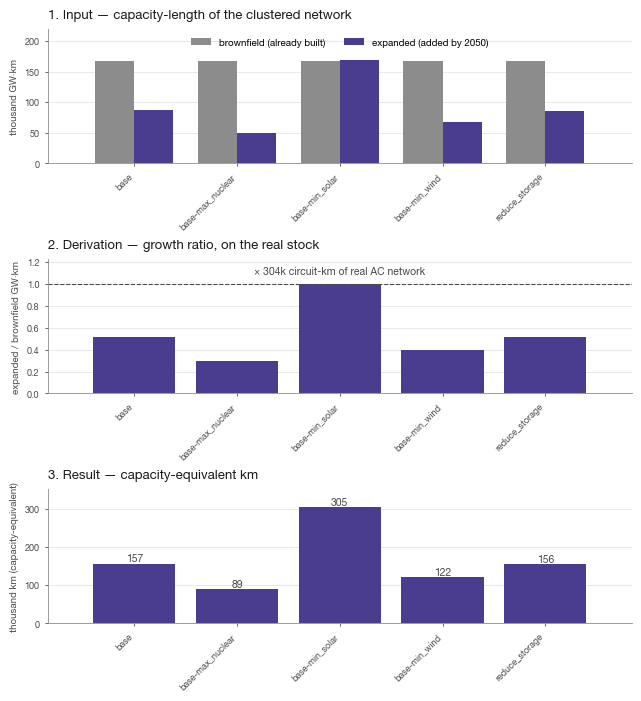

In [3]:
grid = grids[GridType.hv_ac]
table = grid["table"]

fig, axes = stage_figure(
    grid,
    "Input — capacity-length of the clustered network",
    "Derivation — growth ratio, on the real stock",
)

two_series(
    axes[0],
    table[HvAcGridKm.brownfield_gwkm] / 1e3,
    table[HvAcGridKm.expanded_gwkm] / 1e3,
    ("Brownfield (already built)", "Expanded (added by 2050)"),
    grid["color"],
    "Thousand GW·km",
)

circuit_km_full = constant(table, HvAcGridKm.circuit_km_full)
ratio_panel(
    axes[1],
    table[HvAcGridKm.expansion_ratio],
    grid["color"],
    "Expanded / brownfield GW·km",
    f"× {circuit_km_full / 1e3:,.0f}k circuit-km of real AC network",
)

result_panel(axes[2], grid)
plotting.save_figure(fig, figures_dir, "grid_hv_ac_km", style)
plt.show()


## 2. High-voltage DC — `estimate_dc_grid_km`

```
capacity_km  =  expanded_gwkm  ×  clustering_correction  ÷  reference_gw
```

DC links, unlike AC lines, do gain length in the solve — each candidate corridor is
its own link. But a clustered link runs centroid-to-centroid rather than along its
real route, and PyPSA gives links no circuit-length at all. So the expanded
capacity-length is corrected for clustering, then divided by the rating of the
cable the ecoinvent inventory describes.

The correction is measured on the links that **exist today**, the only ones both
reference networks describe: the clustered network additionally carries candidate
corridors, while the full-resolution one describes what is built. Snapping real
routes to straight centroid-to-centroid lines shortens them, so the correction
comes out below 1 and the modelled GW·km is scaled down.

The division is where an assumption enters. A GW·km only becomes a km once a
per-cable rating is chosen; `data/grid_parameters.csv:hvdc_reference_gw` is that
choice. It has to be *this* cable's rating, because the inventory is per km of one
specific design — ecoinvent's own `comment` gives it as 450 kV with 2×790 mm²
copper conductors, and the underlying source (Jorge, Hawkins & Hertwich 2012)
models that on the 700 MW NorNed interconnector. Converter stations have no
ecoinvent dataset and are not counted here.

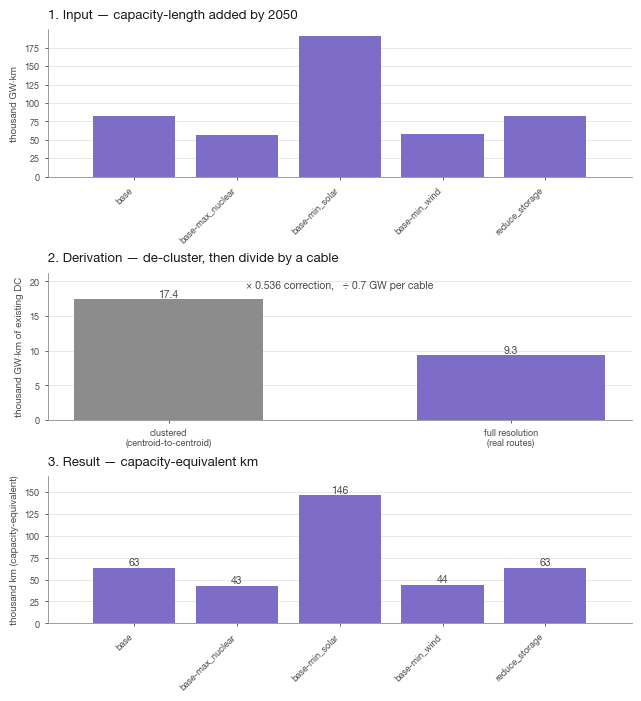

In [4]:
grid = grids[GridType.dc]
table = grid["table"]

fig, axes = stage_figure(
    grid,
    "Input — capacity-length added by 2050",
    "Derivation — de-cluster, then divide by a cable",
)

expanded = table[DcGridKm.expanded_gwkm] / 1e3
axes[0].bar(range(len(expanded)), expanded.values, color=grid["color"])
plotting.style_panel(axes[0], style, title=None, ylabel="Thousand GW·km")
scenario_axis(axes[0], expanded.index)

# One number for every scenario: the DC links that exist today, as each of the two
# reference networks describes them, and the correction that is their ratio.
existing = [
    constant(table, DcGridKm.existing_gwkm_clustered) / 1e3,
    constant(table, DcGridKm.existing_gwkm_full) / 1e3,
]
correction = constant(table, DcGridKm.clustering_correction)
reference_gw = constant(table, DcGridKm.reference_gw)

axes[1].bar([0, 1], existing, width=0.55, color=[GREY, grid["color"]])
plotting.style_panel(
    axes[1], style, title=None, ylabel="Thousand GW·km of existing DC"
)
axes[1].set_xticks(
    [0, 1],
    ["clustered\n(centroid-to-centroid)", "full resolution\n(real routes)"],
    color=ink["secondary"],
)
for i, value in enumerate(existing):
    axes[1].text(i, value, f"{value:,.1f}", va="bottom", ha="center",
                 color=ink["secondary"])
note(axes[1], f"× {correction:.3f} correction,   ÷ {reference_gw} GW per cable")
axes[1].margins(y=0.22)

result_panel(axes[2], grid)
plotting.save_figure(fig, figures_dir, "grid_dc_km", style)
plt.show()


### Where the subsea/land split comes from

The km above are split between two ecoinvent inventories — subsea and land cable —
by a fixed market share in `data/market_share_scenarios.csv`. That split is a rounding
of the measurement below, so it can be re-derived rather than taken on trust.

`measure_hvdc_subsea_share` weights each DC corridor's PyPSA-Eur
`underwater_fraction` by the capacity-length it gains in the solve. The share
drifts a little across scenarios, because different scenarios expand different
corridors, and the frozen split ignores that drift: the two inventories differ by
only ~3 % in the metals that survive (copper, aluminium), so the split moves no
headline number by as much as 0.1 %.

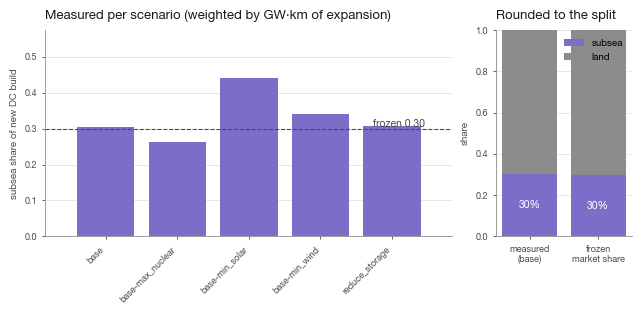

In [5]:
grid = grids[GridType.dc]
subsea = pd.read_csv(paths["subsea_share"]).set_index(HvdcSubseaShare.scenario)
measured = subsea[HvdcSubseaShare.subsea_share]

subsea_sub_technology = next(
    s
    for s in technology_info[grid["technology"]]["sub_technologies"]
    if "subsea" in s.lower()
)
frozen = frozen_shares(grid["technology"])[subsea_sub_technology]
base_scenario = "base" if "base" in measured.index else measured.index[0]

fig, (ax_scen, ax_cmp) = plotting.page_figure(style, ncols=2, width_ratios=[3, 1])

# Left: the measured subsea share per scenario, against the frozen assumption.
ax_scen.bar(range(len(measured)), measured.values, color=grid["color"])
ax_scen.axhline(frozen, color=ink["secondary"], ls="--", lw=0.8)
ax_scen.text(len(measured) - 0.5, frozen, f"Frozen {frozen:.2f} ",
             va="bottom", ha="right", color=ink["secondary"])
plotting.style_panel(
    ax_scen, style,
    title="Measured per scenario (weighted by GW·km of expansion)",
    ylabel="Subsea share of new DC build",
)
scenario_axis(ax_scen, measured.index)
ax_scen.set_ylim(0, max(measured.max(), frozen) * 1.3)

# Right: the base measurement rounded to the frozen split, as 100% stacked bars.
labels = [f"Measured\n({base_scenario})", "Frozen\nmarket share"]
subsea_values = [measured.loc[base_scenario], frozen]
land_values = [1 - value for value in subsea_values]
ax_cmp.bar(labels, subsea_values, color=grid["color"], label="Subsea")
ax_cmp.bar(labels, land_values, bottom=subsea_values, color=GREY, label="Land")
for i, value in enumerate(subsea_values):
    ax_cmp.text(i, value / 2, f"{value:.0%}", ha="center", va="center",
                color=style["ink"]["surface"])
plotting.style_panel(ax_cmp, style, title="Rounded to the split", ylabel="Share")
ax_cmp.set_ylim(0, 1)
ax_cmp.legend(loc="upper right", frameon=False)

plotting.save_figure(fig, figures_dir, "grid_hvdc_subsea_share", style)
plt.show()


## 3. Distribution — `estimate_distribution_grid_km`

```
capacity_km  =  (final_gw / present_gw  −  1)  ×  existing_km
```

The distribution grid reaches km by neither transmission route. PyPSA models it as
one link per node, with no length and no brownfield capacity (`p_nom = 0`), so its
"expanded" capacity is the entire European distribution system rather than an
increment — there is no length to read and no growth to take.

What the link does have is a rating, and a present-day counterpart: the peak of
the exogenous low-voltage load it must already serve. Their ratio is the capacity
growth the scenario implies, and that growth is applied to the existing European
stock, `data/grid_parameters.csv:distribution_existing_km` — 10 million route-km,
from Eurelectric's *Distribution Grids in Europe: Facts and Figures 2020*, covering
the EU-27 less Malta plus Switzerland and the UK. That is a straight multiplier on
every distribution number below, so it is the most consequential single input in
`rules/grid.smk`; the report states it to one significant figure, so a few per cent
here is below the resolution of the source. See `data/source/sources.md`.

Two things about the denominator. It sums each node's own worst hour rather than
peaking the system as a whole: every node has its own link, sized to its own peak
and unable to lend headroom to another, so the diversity-reduced system peak would
flatter the growth. And it counts only the loads PyPSA is given exogenously — EV
charging, heat pumps and home batteries sit behind the same link but are
endogenous 2050 flows with no present-day counterpart, and putting them in the
baseline would measure part of the growth against itself.

The link's optimal rating can be read as the network peak because it is extendable
from zero at a per-MW cost and constrained by `|p_t| ≤ p_nom` at every hour, so
cost minimisation sets it to the smallest value that never binds — exactly the
maximum absolute throughput over the year.

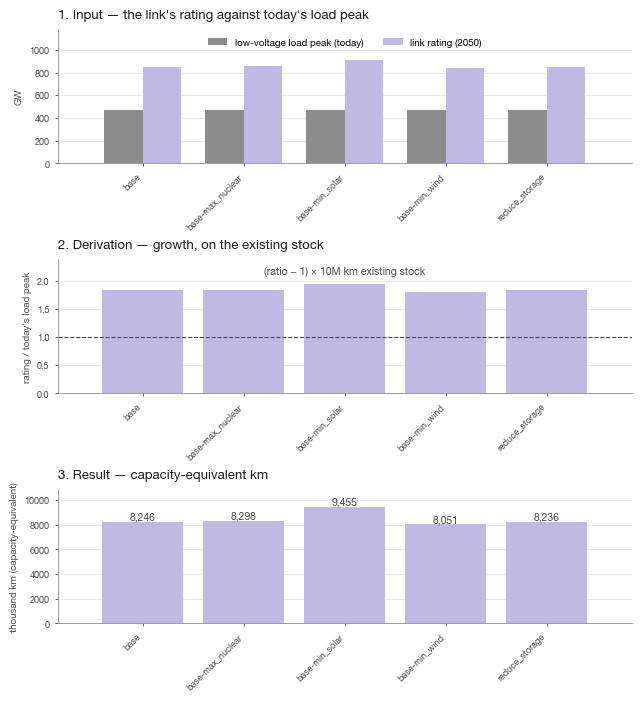

In [6]:
grid = grids[GridType.distribution]
table = grid["table"]

fig, axes = stage_figure(
    grid,
    "Input — the link's rating against today's load peak",
    "Derivation — growth, on the existing stock",
)

two_series(
    axes[0],
    table[DistributionGridKm.present_gw],
    table[DistributionGridKm.final_gw],
    ("Low-voltage load peak (today)", "Link rating (2050)"),
    grid["color"],
    "GW",
)

existing_km = constant(table, DistributionGridKm.existing_km)
ratio_panel(
    axes[1],
    table[DistributionGridKm.growth],
    grid["color"],
    "Rating / today's load peak",
    f"(ratio − 1) × {existing_km / 1e6:g}M km existing stock",
)

result_panel(axes[2], grid)
plotting.save_figure(fig, figures_dir, "grid_distribution_km", style)
plt.show()


### Where the voltage-level split comes from

PyPSA's single distribution link stands for everything below HV transmission,
which in reality spans three voltage levels with very different per-km
inventories. The km above are therefore split across three ecoinvent CH network
datasets by a fixed market share in `data/market_share_scenarios.csv`.

That share is the relative length of the Swiss network behind each dataset — a
number recorded only in the dataset's free-text `comment`, so the cell below reads
it straight out of the Brightway store rather than restating it. It is a Swiss
network split standing in for a European one, which is a real assumption, but it
is the split the inventories themselves were built on.

,dataset,cable_line_km,length_km,measured_share,frozen_share
sub_technology,,,,,
"Grid line, HV AC","transmission network construction, electricity...","[1843, 13988]",15831,0.084591,0.08
"Grid line, MV","transmission network construction, electricity...","[29629, 13042]",42671,0.228007,0.23
"Grid line, LV","distribution network construction, electricity...","[115926, 12720]",128646,0.687402,0.69


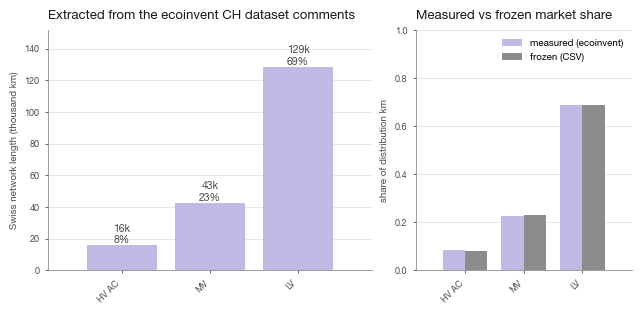

In [7]:
import os
import re

from constants import BRIGHTWAY_STORE  # noqa: E402 — needs the scripts path added above
from IPython.display import display

grid = grids[GridType.distribution]
lci_info = pd.read_csv(paths["lci_info"]).set_index("sub_technology")

# The comment this cell reads exists only on the copper parents; the aluminium
# variants are derived from them and copy the network length untouched.
sub_technologies = [
    s
    for s in technology_info[grid["technology"]]["sub_technologies"]
    if lci_info.loc[s, "database"] == "ecoinvent"
]
dataset_of = {
    s: (lci_info.loc[s, "activity"], lci_info.loc[s, "location"])
    for s in sub_technologies
}

# bw2data reads its data directory from BRIGHTWAY2_DIR at import time, so set it
# (to the repo-local store) before importing.
os.environ["BRIGHTWAY2_DIR"] = str((repo / BRIGHTWAY_STORE).resolve())
import bw2data as bd  # noqa: E402

bd.projects.set_current(lci_project)
db = bd.Database(ecoinvent_db)

# One pass over the database, collecting the comment of each dataset we want.
targets = {name_loc: s for s, name_loc in dataset_of.items()}
comment_of = {
    (a["name"], a["location"]): (a.get("comment", "") or "")
    for a in db
    if (a["name"], a["location"]) in targets
}
missing = [dataset_of[s] for s in sub_technologies if dataset_of[s] not in comment_of]
if missing:
    raise ValueError(f"datasets not found in {ecoinvent_db}: {missing}")

# The Technology: line reports the Swiss network as (cable) + (line) km, e.g.
# "underground cables (29'629km) and aerial lines (13'042km)". Sum every
# parenthesised km figure; fail loudly if a comment has none.
KM_IN_PARENS = re.compile(r"\(([\d'\s]+?)\s*km\)")
rows = []
for sub_technology in sub_technologies:
    name, location = dataset_of[sub_technology]
    parts = KM_IN_PARENS.findall(comment_of[(name, location)])
    if not parts:
        raise ValueError(
            f"no '(... km)' network length in the comment of {name!r} [{location}]"
        )
    lengths = [int(p.replace("'", "").replace(" ", "")) for p in parts]
    rows.append(
        {
            "sub_technology": sub_technology,
            "dataset": name,
            "cable_line_km": lengths,
            "length_km": sum(lengths),
        }
    )

split = pd.DataFrame(rows).set_index("sub_technology")
split["measured_share"] = split["length_km"] / split["length_km"].sum()
split["frozen_share"] = frozen_shares(grid["technology"]).reindex(split.index)
display(split)

levels = [s.replace("Grid line, ", "") for s in split.index]
fig, (ax_len, ax_cmp) = plotting.page_figure(style, ncols=2, width_ratios=[3, 2])

# Left: the Swiss network length each dataset is built from, with its share.
ax_len.bar(range(len(split)), split["length_km"].values / 1e3, color=grid["color"])
plotting.style_panel(
    ax_len, style,
    title="Extracted from the ecoinvent CH dataset comments",
    ylabel="Swiss network length (thousand km)",
)
scenario_axis(ax_len, levels)
for i, (length, share) in enumerate(
    zip(split["length_km"].values, split["measured_share"].values)
):
    ax_len.text(i, length / 1e3, f"{length / 1e3:,.0f}k\n{share:.0%}",
                va="bottom", ha="center", color=ink["secondary"])
ax_len.margins(y=0.18)

# Right: measured (ecoinvent-derived) vs frozen share, per voltage level.
positions = range(len(split))
width = 0.38
ax_cmp.bar([i - width / 2 for i in positions], split["measured_share"].values, width,
           color=grid["color"], label="Measured (ecoinvent)")
ax_cmp.bar([i + width / 2 for i in positions], split["frozen_share"].values, width,
           color=GREY, label="Frozen (CSV)")
plotting.style_panel(
    ax_cmp, style,
    title="Measured vs frozen market share",
    ylabel="Share of distribution km",
)
scenario_axis(ax_cmp, levels)
ax_cmp.set_ylim(0, 1)
ax_cmp.legend(frameon=False)

plotting.save_figure(fig, figures_dir, "grid_distribution_voltage_split", style)
plt.show()


## The three together — `collect_grid_capacity`

The three tables above, stripped of their derivation columns and stacked: one
length per (scenario, technology), which is all `calculate_metal_demand` needs.
Nothing is computed here. The rule only checks that the three grids cover the same
system scenarios, since a scenario missing from one of them would quietly become
a grid with no metal in it.

The magnitudes are worth a look before leaving. Distribution runs roughly two
orders of magnitude above transmission, and it is also the only one of the three
whose length scales an externally sourced stock rather than something measured
inside PyPSA — so most of the grid's metal demand rests on
`data/grid_parameters.csv:distribution_existing_km` and on the load peak its growth
is measured against.

In [8]:
combined = pd.read_csv(paths["combined"])
wide = combined.pivot(
    index=GridCapacity.scenario,
    columns=GridCapacity.technology,
    values=GridCapacity.capacity_km,
).reindex(scenarios)[[grid["technology"] for grid in grids.values()]]

# Thousand km, in the order the sections above walked them.
(wide / 1e3).round(1)

technology,grid_hv_ac,grid_dc,grid_distribution
scenario,,,
base,156.7,63.4,8246.3
base-max_nuclear,89.0,42.9,8298.1
base-min_solar,305.0,145.7,9454.5
base-min_wind,121.6,44.3,8051.3
reduce_storage,155.8,63.3,8235.9
